# PART 1: Q1 Data Preprocessing with Pandas

## 1. Import libraries and load the data

In [1]:
import pandas as pd          # pandas = library for tables (DataFrames)
import numpy as np           # numpy = maths library (used for np.where, np.nan)

df   = pd.read_csv("Dataset_1.csv")    # read the 1st CSV (sales orders) into a table called df
cust = pd.read_csv("Dataset_2.csv")    # read the 2nd CSV (customers) into a table called cust
# Excel file instead?   df = pd.read_excel("file.xlsx")
# Wrong folder?         import os; print(os.listdir())   -> shows the files in this folder

print("----- Data loaded -----")

----- Data loaded -----


## 2. First and last records: `head()` / `tail()`

In [2]:
print("----- First 5 records -----")
print(df.head())          # first 5 rows (df.head(10) -> first 10 rows)

----- First 5 records -----
   OrderID  CustomerID   OrderDate   Product    Category  Quantity  UnitPrice  \
0     1001          16  24-04-2025  Notebook  Stationery       4.0         60   
1     1002          47  23-08-2025     Table   Furniture       5.0       7000   
2     1003          83  14-03-2025     Table   Furniture       5.0       7000   
3     1004          63  09-03-2025  Notebook  Stationery       4.0         60   
4     1005           4  16-11-2025     Table   Furniture       1.0       7000   

     City  
0   delhi  
1   pune   
2   delhi  
3   delhi  
4   Delhi  


In [3]:
print("----- Last 5 records -----")
print(df.tail())          # last 5 rows (df.tail(3) -> last 3 rows)
# Observation: City is written in different ways (delhi / Delhi / " delhi"), so it needs cleaning

----- Last 5 records -----
     OrderID  CustomerID   OrderDate     Product     Category  Quantity  \
305     1128          74  08-07-2025       Phone  Electronics       1.0   
306     1177          80  16-10-2025    Notebook   Stationery       5.0   
307     1074          38  08-10-2025  Headphones  Electronics       2.0   
308     1276          99  19-08-2025       Chair    Furniture       4.0   
309     1243          68  14-07-2025    Notebook   Stationery       5.0   

     UnitPrice    City  
305      20000   Delhi  
306         60   pune   
307       2500    Pune  
308       4000  Mumbai  
309         60     NaN  


## 3. Dimensions, structure, data types: `shape`, `info()`, `dtypes`

In [4]:
print("----- Shape (rows, columns) -----")
print(df.shape)           # (number of rows, number of columns)
print(cust.shape)

print("----- Column names -----")
print(df.columns.tolist())   # list of all column names

----- Shape (rows, columns) -----
(310, 8)
(100, 6)
----- Column names -----
['OrderID', 'CustomerID', 'OrderDate', 'Product', 'Category', 'Quantity', 'UnitPrice', 'City']


In [5]:
print("----- Structure -----")
df.info()                 # column names + non-null count + data type of each column
# Observation: OrderDate is object/str (text), so convert it to datetime.
#              Quantity and City have fewer non-null values, so they have missing values.

----- Structure -----
<class 'pandas.DataFrame'>
RangeIndex: 310 entries, 0 to 309
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   OrderID     310 non-null    int64  
 1   CustomerID  310 non-null    int64  
 2   OrderDate   310 non-null    str    
 3   Product     310 non-null    str    
 4   Category    310 non-null    str    
 5   Quantity    298 non-null    float64
 6   UnitPrice   310 non-null    int64  
 7   City        301 non-null    str    
dtypes: float64(1), int64(3), str(4)
memory usage: 19.5 KB


In [6]:
print("----- Data types -----")
print(df.dtypes)          # only the data type of each column
# int64 = whole numbers, float64 = decimal numbers, object/str = text, datetime64 = date

----- Data types -----
OrderID         int64
CustomerID      int64
OrderDate         str
Product           str
Category          str
Quantity      float64
UnitPrice       int64
City              str
dtype: object


## 4. Descriptive statistics: `describe()`

In [7]:
print("----- Descriptive statistics (numeric columns) -----")
print(df.describe())      # count, mean, std, min, 25%, 50% (median), 75%, max
# Observation: min Quantity = -2 (INVALID) and max UnitPrice = 9999999 (ABNORMAL / outlier)

----- Descriptive statistics (numeric columns) -----
           OrderID  CustomerID    Quantity     UnitPrice
count   310.000000  310.000000  298.000000  3.100000e+02
mean   1151.190323   50.029032    2.912752  7.596038e+04
std      86.099246   27.808682    1.510604  8.011892e+05
min    1001.000000    2.000000   -2.000000  2.000000e+01
25%    1077.250000   27.000000    2.000000  6.000000e+01
50%    1151.500000   47.000000    3.000000  4.000000e+03
75%    1224.750000   76.000000    4.000000  2.000000e+04
max    1300.000000  100.000000    5.000000  9.999999e+06


In [8]:
print("----- Statistics for text columns -----")
print(df.describe(exclude="number"))   # text columns: count, unique, top (most common), freq
# df.describe(include="all") -> numbers + text together

----- Statistics for text columns -----
         OrderDate   Product     Category    City
count          310       310          310     301
unique         207         7            3       7
top     05-10-2025  Notebook  Electronics   delhi
freq             5        57          119      56


In [9]:
print("----- Single statistics -----")
print("Mean    :", df["UnitPrice"].mean())     # average
print("Median  :", df["UnitPrice"].median())   # middle value
print("Mode    :", df["Category"].mode()[0])   # most frequent value
print("Std dev :", df["UnitPrice"].std())      # spread
print("Min/Max :", df["UnitPrice"].min(), df["UnitPrice"].max())
# Observation: mean is much bigger than median because of the outlier 9999999

----- Single statistics -----
Mean    : 75960.38064516129
Median  : 4000.0
Mode    : Electronics
Std dev : 801189.2300561205
Min/Max : 20 9999999


## 5. Missing values: `isnull()`, `fillna()`, `dropna()`

In [10]:
print("----- Missing values BEFORE -----")
print(df.isnull().sum())                     # number of missing (NaN) values in each column
print("Dataset_2:\n", cust.isnull().sum())
print("% missing:\n", (df.isnull().mean() * 100).round(2))   # percentage missing

----- Missing values BEFORE -----
OrderID        0
CustomerID     0
OrderDate      0
Product        0
Category       0
Quantity      12
UnitPrice      0
City           9
dtype: int64
Dataset_2:
 CustomerID    0
Name          0
Gender        0
Age           5
Income        0
Purchased     0
dtype: int64
% missing:
 OrderID       0.00
CustomerID    0.00
OrderDate     0.00
Product       0.00
Category      0.00
Quantity      3.87
UnitPrice     0.00
City          2.90
dtype: float64


In [11]:
# NUMBER column -> fill with the median (median is not affected by outliers)
df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())
cust["Age"]    = cust["Age"].fillna(cust["Age"].median())
# (or the mean:  df["Quantity"].fillna(df["Quantity"].mean()))

# TEXT column -> fill with a word, or the mode (most common value)
df["City"] = df["City"].fillna("Unknown")
# df["City"] = df["City"].fillna(df["City"].mode()[0])

# Other options (don't run all of these, just know them):
# df = df.dropna()                       # delete every row that has ANY missing value
# df = df.dropna(subset=["Quantity"])    # delete rows only where Quantity is missing
# df["Quantity"] = df["Quantity"].ffill()   # forward fill: copy the value from the row above

print("----- Missing values AFTER -----")
print(df.isnull().sum())                     # should be all 0 now
print("Dataset_2 total missing:", cust.isnull().sum().sum())

----- Missing values AFTER -----
OrderID       0
CustomerID    0
OrderDate     0
Product       0
Category      0
Quantity      0
UnitPrice     0
City          0
dtype: int64
Dataset_2 total missing: 0


## 6. Duplicates: `duplicated()`, `drop_duplicates()`

In [12]:
print("----- Duplicates -----")
print("Number of duplicate rows:", df.duplicated().sum())   # True for a row that is an exact copy of an earlier row
print("Shape before:", df.shape)
df = df.drop_duplicates()                    # remove the duplicate rows (the first copy is kept)
# df = df.drop_duplicates(subset=["OrderID"])   # duplicates based on one column only
print("Shape after :", df.shape)

----- Duplicates -----
Number of duplicate rows: 10
Shape before: (310, 8)
Shape after : (300, 8)


## 7. Text cleaning / standardisation: `.str.strip()`, `.str.title()`, `replace()`

In [13]:
print("----- City BEFORE -----")
print(df["City"].value_counts())             # see all the different spellings

df["City"] = df["City"].str.strip().str.title()   # strip = remove spaces at both ends, title = "Capital First Letter"

print("----- City AFTER -----")
print(df["City"].value_counts())
# Observation: 7 spellings became 4 real cities (+ Unknown)

----- City BEFORE -----
City
 delhi     56
Delhi      51
Pune       42
MUMBAI     40
pune       39
Nagpur     34
Mumbai     30
Unknown     8
Name: count, dtype: int64
----- City AFTER -----
City
Delhi      107
Pune        81
Mumbai      70
Nagpur      34
Unknown      8
Name: count, dtype: int64


In [14]:
print("----- Gender BEFORE -----")
print(cust["Gender"].value_counts())

cust["Gender"] = (cust["Gender"].str.strip()            # remove spaces
                  .str.title()                          # male -> Male
                  .replace({"F": "Female", "M": "Male"})) # short forms -> full words

print("----- Gender AFTER -----")
print(cust["Gender"].value_counts())
# Other string tools: .str.lower()  .str.upper()  .str.replace("-", " ")  .str.len()  .str[:3]

----- Gender BEFORE -----
Gender
male      29
F         29
Female    25
Male      17
Name: count, dtype: int64
----- Gender AFTER -----
Gender
Female    54
Male      46
Name: count, dtype: int64


## 8. Invalid and abnormal values (outliers)

In [15]:
print("----- Invalid rows (Quantity <= 0) -----")
print(df[df["Quantity"] <= 0])               # a quantity can't be zero or negative

print("----- Abnormal rows (UnitPrice > 100000) -----")
print(df[df["UnitPrice"] > 100000])          # an impossibly high price

df = df[df["Quantity"] > 0].copy()           # keep only the valid rows (.copy() avoids a warning)
df = df[df["UnitPrice"] < 100000].copy()     # keep only the normal prices
print("Shape after removing:", df.shape)

# Alternative: REPLACE an invalid value instead of deleting the row
# df.loc[df["Quantity"] < 0, "Quantity"] = df["Quantity"].median()

----- Invalid rows (Quantity <= 0) -----
     OrderID  CustomerID   OrderDate   Product     Category  Quantity  \
64      1065          25  05-12-2025  Notebook   Stationery      -2.0   
121     1122          71  08-04-2025     Table    Furniture      -2.0   
257     1258          78  20-09-2025     Phone  Electronics      -2.0   
266     1267          28  27-05-2025    Laptop  Electronics      -2.0   

     UnitPrice    City  
64          60   Delhi  
121       7000  Mumbai  
257      20000   Delhi  
266      55000    Pune  
----- Abnormal rows (UnitPrice > 100000) -----
    OrderID  CustomerID   OrderDate Product     Category  Quantity  UnitPrice  \
18     1019          93  05-05-2025  Laptop  Electronics       1.0    9999999   
92     1093          23  16-04-2025   Chair    Furniture       1.0    9999999   

    City  
18  Pune  
92  Pune  
Shape after removing: (294, 8)


In [16]:
print("----- Outliers with the IQR method (standard rule) -----")
Q1 = df["UnitPrice"].quantile(0.25)          # 25th percentile
Q3 = df["UnitPrice"].quantile(0.75)          # 75th percentile
IQR = Q3 - Q1                                # inter-quartile range
lower = Q1 - 1.5 * IQR                       # anything below this is an outlier
upper = Q3 + 1.5 * IQR                       # anything above this is an outlier
print("Q1:", Q1, " Q3:", Q3, " IQR:", IQR, " lower:", lower, " upper:", upper)

outliers = df[(df["UnitPrice"] < lower) | (df["UnitPrice"] > upper)]
print("Outlier rows by IQR:", len(outliers))
# Remove them: df = df[(df["UnitPrice"] >= lower) & (df["UnitPrice"] <= upper)]
# Cap them   : df["UnitPrice"] = df["UnitPrice"].clip(lower, upper)
# NOTE: here IQR also flags Laptop (55000), which is a REAL price, so always check before deleting.

----- Outliers with the IQR method (standard rule) -----
Q1: 60.0  Q3: 20000.0  IQR: 19940.0  lower: -29850.0  upper: 49910.0
Outlier rows by IQR: 38


## 9. Date conversion and year extraction: `pd.to_datetime()`, `.dt`

In [17]:
print("Type BEFORE:", df["OrderDate"].dtype)          # text

df["OrderDate"] = pd.to_datetime(df["OrderDate"], dayfirst=True)   # dayfirst=True because the dates are dd-mm-yyyy
# with an exact format: pd.to_datetime(df["OrderDate"], format="%d-%m-%Y")
# if some dates are bad: pd.to_datetime(df["OrderDate"], errors="coerce")  -> bad ones become NaT

print("Type AFTER :", df["OrderDate"].dtype)          # datetime64

df["Year"]      = df["OrderDate"].dt.year             # 2025
df["Month"]     = df["OrderDate"].dt.month            # 1-12
df["MonthName"] = df["OrderDate"].dt.month_name()     # January...
df["Day"]       = df["OrderDate"].dt.day_name()       # Monday...
df["Quarter"]   = df["OrderDate"].dt.quarter          # 1-4

print(df[["OrderDate", "Year", "Month", "MonthName", "Day", "Quarter"]].head())

Type BEFORE: str
Type AFTER : datetime64[us]
   OrderDate  Year  Month MonthName       Day  Quarter
0 2025-04-24  2025      4     April  Thursday        2
1 2025-08-23  2025      8    August  Saturday        3
2 2025-03-14  2025      3     March    Friday        1
3 2025-03-09  2025      3     March    Sunday        1
4 2025-11-16  2025     11  November    Sunday        4


## 10. Calculated columns and mathematical operations

In [18]:
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]      # new column = Quantity x Price
df["Discount"]    = df["TotalAmount"] * 0.10              # 10% discount
df["NetAmount"]   = df["TotalAmount"] - df["Discount"]    # after discount
df["GST"]         = (df["NetAmount"] * 0.18).round(2)     # 18% tax, rounded to 2 decimals

print(df[["Quantity", "UnitPrice", "TotalAmount", "Discount", "NetAmount", "GST"]].head())
print("Total sales :", df["TotalAmount"].sum())
print("Average     :", round(df["TotalAmount"].mean(), 2))
print("Max / Min   :", df["TotalAmount"].max(), df["TotalAmount"].min())

   Quantity  UnitPrice  TotalAmount  Discount  NetAmount      GST
0       4.0         60        240.0      24.0      216.0    38.88
1       5.0       7000      35000.0    3500.0    31500.0  5670.00
2       5.0       7000      35000.0    3500.0    31500.0  5670.00
3       4.0         60        240.0      24.0      216.0    38.88
4       1.0       7000       7000.0     700.0     6300.0  1134.00
Total sales : 10567140.0
Average     : 35942.65
Max / Min   : 275000.0 20.0


In [19]:
# IF / ELSE column -> np.where(condition, value_if_true, value_if_false)
df["OrderSize"] = np.where(df["TotalAmount"] >= 20000, "Big", "Small")
print(df["OrderSize"].value_counts())

# Number ranges -> labels with pd.cut
df["PriceBand"] = pd.cut(df["UnitPrice"], bins=[0, 1000, 10000, 100000],
                         labels=["Low", "Medium", "High"])
print(df["PriceBand"].value_counts())

# Your own rule with apply + lambda
df["QtyType"] = df["Quantity"].apply(lambda q: "Bulk" if q >= 4 else "Normal")
print(df["QtyType"].value_counts())

# Change a data type
df["Quantity"] = df["Quantity"].astype(int)          # 4.0 -> 4

OrderSize
Small    182
Big      112
Name: count, dtype: int64
PriceBand
Medium    124
Low        94
High       76
Name: count, dtype: int64
QtyType
Normal    184
Bulk      110
Name: count, dtype: int64


## 11. Filtering with conditions

In [20]:
print("----- One condition: Electronics only -----")
elec = df[df["Category"] == "Electronics"]           # == equal, != not equal, > < >= <=
print(elec.shape)

print("----- AND: Pune AND TotalAmount > 10000 -----")
r = df[(df["City"] == "Pune") & (df["TotalAmount"] > 10000)]   # & = AND, brackets around each condition!
print(r[["OrderID", "City", "Product", "TotalAmount"]].head())
print("Rows:", len(r))

----- One condition: Electronics only -----
(113, 20)
----- AND: Pune AND TotalAmount > 10000 -----
    OrderID  City     Product  TotalAmount
1      1002  Pune       Table      35000.0
8      1009  Pune      Laptop     165000.0
21     1022  Pune  Headphones      12500.0
27     1028  Pune       Chair      12000.0
32     1033  Pune       Chair      20000.0
Rows: 41


In [21]:
print("----- OR: Pune OR Delhi -----")
print(len(df[(df["City"] == "Pune") | (df["City"] == "Delhi")]))   # | = OR

print("----- isin: value in a list -----")
print(len(df[df["City"].isin(["Pune", "Delhi"])]))                 # same result as the OR above

print("----- NOT -----")
print(len(df[~df["City"].isin(["Unknown"])]))                      # ~ = NOT

print("----- Text contains -----")
print(df[df["Product"].str.contains("Phone")]["Product"].unique())

print("----- Between a range -----")
print(len(df[df["UnitPrice"].between(1000, 10000)]))

print("----- query() (easy-to-read way) -----")
print(len(df.query("Quantity >= 5 and Category == 'Furniture'")))

----- OR: Pune OR Delhi -----
183
----- isin: value in a list -----
183
----- NOT -----
286
----- Text contains -----
<StringArray>
['Phone']
Length: 1, dtype: str
----- Between a range -----
124
----- query() (easy-to-read way) -----
20


## 12. Sorting and top records

In [22]:
print("----- Top 5 orders by TotalAmount -----")
print(df.sort_values("TotalAmount", ascending=False).head(5)[["OrderID", "Product", "City", "TotalAmount"]])
# ascending=False -> biggest first; ascending=True -> smallest first

print("----- Same with nlargest -----")
print(df.nlargest(5, "TotalAmount")[["OrderID", "TotalAmount"]])

print("----- Bottom 3 -----")
print(df.nsmallest(3, "TotalAmount")[["OrderID", "TotalAmount"]])

print("----- Sort by 2 columns -----")
print(df.sort_values(["City", "TotalAmount"], ascending=[True, False])[["City", "TotalAmount"]].head())

----- Top 5 orders by TotalAmount -----
     OrderID Product    City  TotalAmount
146     1147  Laptop  Mumbai     275000.0
135     1136  Laptop   Delhi     275000.0
292     1293  Laptop   Delhi     275000.0
104     1105  Laptop    Pune     275000.0
268     1269  Laptop  Nagpur     220000.0
----- Same with nlargest -----
     OrderID  TotalAmount
104     1105     275000.0
135     1136     275000.0
146     1147     275000.0
292     1293     275000.0
46      1047     220000.0
----- Bottom 3 -----
    OrderID  TotalAmount
34     1035         20.0
35     1036         20.0
96     1097         20.0
----- Sort by 2 columns -----
      City  TotalAmount
135  Delhi     275000.0
292  Delhi     275000.0
105  Delhi     220000.0
197  Delhi     220000.0
202  Delhi     220000.0


## 13. Unique and distinct values

In [23]:
print("Unique cities   :", df["City"].unique())       # the distinct values
print("How many unique :", df["City"].nunique())      # count of distinct values
print("----- Count of each -----")
print(df["Category"].value_counts())                  # how many times each value appears
print("----- As percentage -----")
print((df["Category"].value_counts(normalize=True) * 100).round(2))

Unique cities   : <StringArray>
['Delhi', 'Pune', 'Mumbai', 'Unknown', 'Nagpur']
Length: 5, dtype: str
How many unique : 5
----- Count of each -----
Category
Electronics    113
Stationery      94
Furniture       87
Name: count, dtype: int64
----- As percentage -----
Category
Electronics    38.44
Stationery     31.97
Furniture      29.59
Name: proportion, dtype: float64


## 14. Selecting rows and columns: `[]`, `loc`, `iloc`

In [24]:
print(df["City"].head(3))                              # one column -> single brackets
print(df[["OrderID", "Product", "TotalAmount"]].head(3))  # many columns -> DOUBLE brackets
print(df.iloc[0:3, 0:4])                               # iloc = by POSITION: rows 0-2, columns 0-3
print(df.loc[df["Quantity"] == 5, ["OrderID", "Product"]].head(3))  # loc = by CONDITION / NAME
print(df.iloc[0])                                      # the first row

0    Delhi
1     Pune
2    Delhi
Name: City, dtype: str
   OrderID   Product  TotalAmount
0     1001  Notebook        240.0
1     1002     Table      35000.0
2     1003     Table      35000.0
   OrderID  CustomerID  OrderDate   Product
0     1001          16 2025-04-24  Notebook
1     1002          47 2025-08-23     Table
2     1003          83 2025-03-14     Table
    OrderID Product
1      1002   Table
2      1003   Table
14     1015   Chair
OrderID                       1001
CustomerID                      16
OrderDate      2025-04-24 00:00:00
Product                   Notebook
Category                Stationery
Quantity                         4
UnitPrice                       60
City                         Delhi
Year                          2025
Month                            4
MonthName                    April
Day                       Thursday
Quarter                          2
TotalAmount                  240.0
Discount                      24.0
NetAmount                  

## 15. Renaming, dropping and reordering columns

In [25]:
df = df.rename(columns={"UnitPrice": "Price"})        # old name -> new name
df = df.drop(columns=["QtyType", "GST"])              # delete columns
df.columns = df.columns.str.strip()                   # remove hidden spaces from the column names
print(df.columns.tolist())

['OrderID', 'CustomerID', 'OrderDate', 'Product', 'Category', 'Quantity', 'Price', 'City', 'Year', 'Month', 'MonthName', 'Day', 'Quarter', 'TotalAmount', 'Discount', 'NetAmount', 'OrderSize', 'PriceBand']


## 16. Grouping and aggregation: `groupby()`

In [26]:
print("----- Total sales per Category -----")
print(df.groupby("Category")["TotalAmount"].sum())

print("----- Average sales per City -----")
print(df.groupby("City")["TotalAmount"].mean().round(2))

print("----- Many aggregations at once -----")
print(df.groupby("Category").agg(Total=("TotalAmount", "sum"),     # new_name=(column, function)
                                 Orders=("OrderID", "count"),
                                 AvgQty=("Quantity", "mean")).round(2))

----- Total sales per Category -----
Category
Electronics    9125000.0
Furniture      1431000.0
Stationery       11140.0
Name: TotalAmount, dtype: float64
----- Average sales per City -----
City
Delhi      37987.24
Mumbai     25200.29
Nagpur     35714.71
Pune       45153.33
Unknown    12925.00
Name: TotalAmount, dtype: float64
----- Many aggregations at once -----
                 Total  Orders  AvgQty
Category                              
Electronics  9125000.0     113    3.06
Furniture    1431000.0      87    3.07
Stationery     11140.0      94    2.86


In [27]:
print("----- sum, mean, count, min, max together -----")
print(df.groupby("Category")["TotalAmount"].agg(["sum", "mean", "count", "min", "max"]))

print("----- Group by 2 columns (monthly trend) -----")
print(df.groupby(["Year", "Month"])["TotalAmount"].sum())

print("----- Best city first -----")
print(df.groupby("City")["TotalAmount"].sum().sort_values(ascending=False))
# Observation: Electronics gives the most revenue; Delhi is the top city

----- sum, mean, count, min, max together -----
                   sum          mean  count     min       max
Category                                                     
Electronics  9125000.0  80752.212389    113  2500.0  275000.0
Furniture    1431000.0  16448.275862     87  4000.0   35000.0
Stationery     11140.0    118.510638     94    20.0     300.0
----- Group by 2 columns (monthly trend) -----
Year  Month
2025  1        1282180.0
      2         537000.0
      3         699680.0
      4         722260.0
      5         788620.0
      6        1045040.0
      7         607980.0
      8         286440.0
      9         332140.0
      10       1276000.0
      11       1357800.0
      12       1632000.0
Name: TotalAmount, dtype: float64
----- Best city first -----
City
Delhi      3988660.0
Pune       3521960.0
Mumbai     1738820.0
Nagpur     1214300.0
Unknown     103400.0
Name: TotalAmount, dtype: float64


## 17. Pivot table and crosstab

In [28]:
print("----- Pivot: total sales, City x Category -----")
print(pd.pivot_table(df, values="TotalAmount", index="City", columns="Category",
                     aggfunc="sum", fill_value=0))     # like an Excel pivot table

print("----- Crosstab: number of orders, City x Category -----")
print(pd.crosstab(df["City"], df["Category"]))

----- Pivot: total sales, City x Category -----
Category  Electronics  Furniture  Stationery
City                                        
Delhi       3432500.0   553000.0      3160.0
Mumbai      1517500.0   218000.0      3320.0
Nagpur       995000.0   218000.0      1300.0
Pune        3112500.0   407000.0      2460.0
Unknown       67500.0    35000.0       900.0
----- Crosstab: number of orders, City x Category -----


Category  Electronics  Furniture  Stationery
City                                        
Delhi              40         32          33
Mumbai             27         16          26
Nagpur             11         13          10
Pune               33         24          21
Unknown             2          2           4


## 18. Merging two datasets on a common key: `pd.merge()`

In [29]:
merged = pd.merge(df, cust, on="CustomerID", how="left")   # join on the common column CustomerID
# how="inner" -> only rows that match in both tables
# how="left"  -> all rows of df (left), plus matching customer info
# how="right" -> all rows of cust
# how="outer" -> everything from both
# different key names: pd.merge(df, cust, left_on="CustID", right_on="CustomerID")

print("Shape after merge:", merged.shape)
print(merged[["OrderID", "CustomerID", "Product", "Name", "Gender", "Age"]].head())

Shape after merge: (294, 23)
   OrderID  CustomerID   Product         Name  Gender   Age
0     1001          16  Notebook  Customer 16    Male  40.0
1     1002          47     Table  Customer 47  Female  57.0
2     1003          83     Table  Customer 83  Female  28.0
3     1004          63  Notebook  Customer 63    Male  51.0
4     1005           4     Table   Customer 4  Female  24.0


## 19. Splitting and recombining: `pd.concat()`

In [30]:
part1 = df[df["Category"] == "Electronics"]             # split into 2 parts
part2 = df[df["Category"] != "Electronics"]
combined = pd.concat([part1, part2], ignore_index=True)  # stack rows back together
print("Part1:", len(part1), " Part2:", len(part2), " Combined:", len(combined))

# side by side (columns): pd.concat([a, b], axis=1)
# split a text column:
parts = cust["Name"].str.split(" ", expand=True)        # "Customer 1" -> ["Customer", "1"]
print(parts.head(3))

Part1: 113  Part2: 181  Combined: 294
          0  1
0  Customer  1
1  Customer  2
2  Customer  3


## 20. Correlation

In [31]:
print(merged[["Quantity", "Price", "TotalAmount", "Age", "Income"]].corr().round(2))
# +1 = strong positive, 0 = no relation, -1 = strong negative
# Observation: Age and Income = 0.83 -> strong positive relationship

             Quantity  Price  TotalAmount   Age  Income
Quantity         1.00   0.05         0.26  0.09   -0.02
Price            0.05   1.00         0.91  0.01   -0.02
TotalAmount      0.26   0.91         1.00 -0.02   -0.06
Age              0.09   0.01        -0.02  1.00    0.83
Income          -0.02  -0.02        -0.06  0.83    1.00


## 21. Export the clean data to CSV

In [32]:
merged.to_csv("cleaned_data.csv", index=False)   # index=False -> don't save the row numbers
print("Saved cleaned_data.csv, shape:", merged.shape)
# Download from Colab:  from google.colab import files; files.download("cleaned_data.csv")

Saved cleaned_data.csv, shape: (294, 23)


## A. Import ML libraries

In [33]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score   # split data, cross-validation
from sklearn.preprocessing import StandardScaler, LabelEncoder          # scaling, text -> number
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,   # classification metrics
                             r2_score, mean_absolute_error, mean_squared_error)         # regression metrics
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
print("ML libraries imported")

ML libraries imported


## B. Step 1: Load and look

In [34]:
data = pd.read_csv("Dataset_2.csv")      # customer data
print(data.head())
print("Shape:", data.shape)
print("Missing:\n", data.isnull().sum())
print("Target counts:\n", data["Purchased"].value_counts())
# Observation: the target Purchased is Yes/No, so this is a CLASSIFICATION problem

   CustomerID        Name  Gender   Age   Income Purchased
0           1  Customer 1  Female  41.0  55300.0       Yes
1           2  Customer 2  Female  29.0  44200.0        No
2           3  Customer 3    male  38.0  52500.0       Yes
3           4  Customer 4       F  24.0  24900.0        No
4           5  Customer 5  Female  63.0  70400.0       Yes
Shape: (100, 6)
Missing:
 CustomerID    0
Name          0
Gender        0
Age           5
Income        0
Purchased     0
dtype: int64
Target counts:
 Purchased
Yes    79
No     21
Name: count, dtype: int64


## C. Step 2: Prepare (no missing values; text → numbers)

In [35]:
data["Age"] = data["Age"].fillna(data["Age"].median())            # ML models can't handle NaN

data["Gender"] = data["Gender"].str.strip().str.title().replace({"F": "Female"})   # clean first
data["Gender"] = data["Gender"].map({"Male": 0, "Female": 1})                     # text -> number
data["Purchased"] = data["Purchased"].map({"No": 0, "Yes": 1})                    # target -> 0/1

print(data.head())
print("Missing left:", data.isnull().sum().sum())

# Alternative 1, LabelEncoder (alphabetical order: No=0, Yes=1):
#   le = LabelEncoder(); data["Purchased"] = le.fit_transform(data["Purchased"])
# Alternative 2, many categories (City/Category) -> one-hot dummy columns:
#   data = pd.get_dummies(data, columns=["City"], drop_first=True, dtype=int)

   CustomerID        Name  Gender   Age   Income  Purchased
0           1  Customer 1       1  41.0  55300.0          1
1           2  Customer 2       1  29.0  44200.0          0
2           3  Customer 3       0  38.0  52500.0          1
3           4  Customer 4       1  24.0  24900.0          0
4           5  Customer 5       1  63.0  70400.0          1
Missing left: 0


## D. Step 3: Features (X) and target (y)

In [36]:
X = data[["Age", "Income", "Gender"]]    # inputs (never include ID / Name columns)
y = data["Purchased"]                    # output we want to predict
print("X shape:", X.shape, " y shape:", y.shape)

X shape: (100, 3)  y shape: (100,)


## E. Step 4: Train/test split + feature scaling

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,        # 20% test, 80% train
    random_state=42)      # same split every run (reproducible)
# add stratify=y to keep the same Yes/No ratio in train and test
print("Train:", X_train.shape, " Test:", X_test.shape)

sc = StandardScaler()                 # makes each column mean 0, std 1
X_train_s = sc.fit_transform(X_train) # learn mean/std from TRAIN only, then transform
X_test_s  = sc.transform(X_test)      # use the same mean/std on test (no data leakage)
print(X_train_s[:3].round(2))
# Scaling is NEEDED for KNN, SVM and Logistic Regression (they use distances); trees don't need it

Train: (80, 3)  Test: (20, 3)
[[-1.19 -0.61  0.95]
 [-0.96 -0.97  0.95]
 [ 1.73  0.74 -1.05]]


## F. Logistic Regression

In [38]:
log_model = LogisticRegression()           # create the model
log_model.fit(X_train_s, y_train)          # Step 5: train
log_pred = log_model.predict(X_test_s)     # Step 6: predict on test data

print("Logistic Regression accuracy:", accuracy_score(y_test, log_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, log_pred))
print("Probabilities [P(No), P(Yes)] for the first 3:\n", log_model.predict_proba(X_test_s[:3]).round(2))
print("Coefficients (Age, Income, Gender):", log_model.coef_.round(2))
# Idea: S-shaped sigmoid curve gives a probability; > 0.5 -> class 1

Logistic Regression accuracy: 0.9
Confusion matrix:
 [[ 2  2]
 [ 0 16]]
Probabilities [P(No), P(Yes)] for the first 3:
 [[0.03 0.97]
 [0.   1.  ]
 [0.04 0.96]]
Coefficients (Age, Income, Gender): [[0.52 1.72 0.22]]


## G. Decision Tree

In [39]:
dt_model = DecisionTreeClassifier(random_state=42)   # max_depth=3 limits the depth (less overfitting)
dt_model.fit(X_train_s, y_train)
dt_pred = dt_model.predict(X_test_s)

print("Train accuracy:", accuracy_score(y_train, dt_model.predict(X_train_s)))   # usually 1.0
print("Test  accuracy:", accuracy_score(y_test, dt_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, dt_pred))
# Observation: train 100% but test lower -> OVERFITTING (it memorised the training data)

Train accuracy: 1.0
Test  accuracy: 0.8
Confusion matrix:
 [[ 1  3]
 [ 1 15]]


In [40]:
print("----- Effect of max_depth -----")
for d in [2, 3, 5, None]:                       # None = grow the full tree
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train_s, y_train)
    print("depth", d, "| train", round(accuracy_score(y_train, t.predict(X_train_s)), 2),
          "| test", round(accuracy_score(y_test, t.predict(X_test_s)), 2))

----- Effect of max_depth -----
depth 2 | train 0.88 | test 0.85
depth 3 | train 0.9 | test 0.8
depth 5 | train 0.94 | test 0.75
depth None | train 1.0 | test 0.8


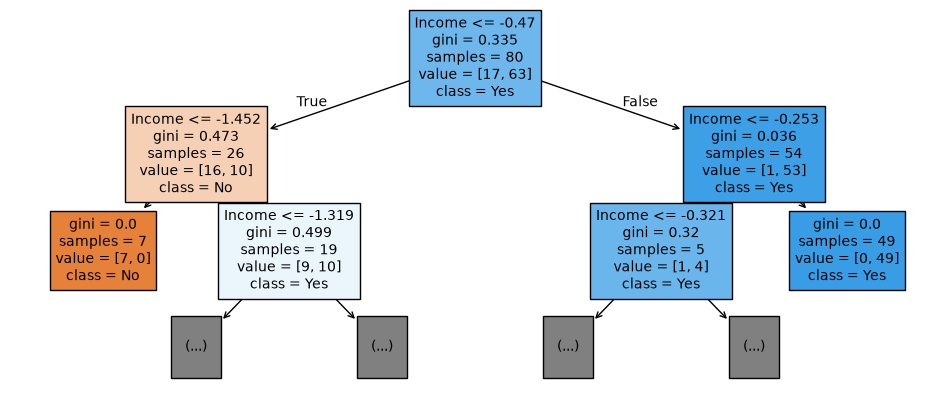

In [41]:
# Draw the tree (top 2 levels)
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plt.figure(figsize=(12, 5))
plot_tree(dt_model, feature_names=X.columns, class_names=["No", "Yes"], filled=True, max_depth=2)
plt.show()

## H. Random Forest

In [42]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)   # 100 trees that vote
rf_model.fit(X_train_s, y_train)
rf_pred = rf_model.predict(X_test_s)

print("Random Forest accuracy:", accuracy_score(y_test, rf_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, rf_pred))
print("----- Feature importance (which column matters most) -----")
print(pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).round(3))
# Idea: many trees on random samples, majority vote -> less overfitting than one tree

Random Forest accuracy: 0.85
Confusion matrix:
 [[ 2  2]
 [ 1 15]]
----- Feature importance (which column matters most) -----
Income    0.578
Age       0.385
Gender    0.038
dtype: float64


## I. KNN (K-Nearest Neighbours)

In [43]:
knn_model = KNeighborsClassifier(n_neighbors=5)     # look at the 5 nearest points
knn_model.fit(X_train_s, y_train)
knn_pred = knn_model.predict(X_test_s)
print("KNN accuracy:", accuracy_score(y_test, knn_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, knn_pred))

print("----- Choosing the best K -----")
for k in [1, 3, 5, 7, 9, 11]:                       # odd K avoids ties
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    print("K =", k, " accuracy =", round(accuracy_score(y_test, m.predict(X_test_s)), 2))
# Idea: majority class of the K closest points; NEEDS scaling

KNN accuracy: 0.95
Confusion matrix:
 [[ 3  1]
 [ 0 16]]
----- Choosing the best K -----
K = 1  accuracy = 0.85
K = 3  accuracy = 0.85
K = 5  accuracy = 0.95
K = 7  accuracy = 0.9
K = 9  accuracy = 0.9
K = 11  accuracy = 0.9


## J. SVM (Support Vector Machine)

In [44]:
svm_model = SVC(kernel="rbf")                        # rbf = default kernel (curved boundary)
svm_model.fit(X_train_s, y_train)
svm_pred = svm_model.predict(X_test_s)
print("SVM accuracy:", accuracy_score(y_test, svm_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, svm_pred))

print("----- Try different kernels -----")
for k in ["linear", "rbf", "poly"]:
    m = SVC(kernel=k).fit(X_train_s, y_train)
    print(k, round(accuracy_score(y_test, m.predict(X_test_s)), 2))
# Idea: the boundary (hyperplane) with the widest margin; the closest points = support vectors

SVM accuracy: 0.85
Confusion matrix:
 [[ 1  3]
 [ 0 16]]
----- Try different kernels -----
linear 0.9
rbf 0.85
poly 0.85


## K. Compare all models (gets marks!)

In [45]:
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree":       DecisionTreeClassifier(random_state=42),
    "Random Forest":       RandomForestClassifier(random_state=42),
    "KNN":                 KNeighborsClassifier(n_neighbors=5),
    "SVM":                 SVC(),
}
results = {}                                          # empty dictionary to store the scores
for name, m in models.items():                        # loop over every model
    m.fit(X_train_s, y_train)                         # train
    results[name] = accuracy_score(y_test, m.predict(X_test_s))   # test accuracy

table = pd.Series(results).sort_values(ascending=False).round(2)
print("----- Accuracy comparison -----")
print(table)
print("Best model:", table.idxmax())

----- Accuracy comparison -----
KNN                    0.95
Logistic Regression    0.90
Random Forest          0.85
SVM                    0.85
Decision Tree          0.80
dtype: float64
Best model: KNN


In [46]:
print("----- 5-fold cross-validation (more reliable than one split) -----")
X_all_s = StandardScaler().fit_transform(X)
for name, m in models.items():
    scores = cross_val_score(m, X_all_s, y, cv=5)     # train/test 5 times on different parts
    print(f"{name:20s} mean = {scores.mean():.2f}")

----- 5-fold cross-validation (more reliable than one split) -----
Logistic Regression  mean = 0.86
Decision Tree        mean = 0.83


Random Forest        mean = 0.82
KNN                  mean = 0.82
SVM                  mean = 0.82


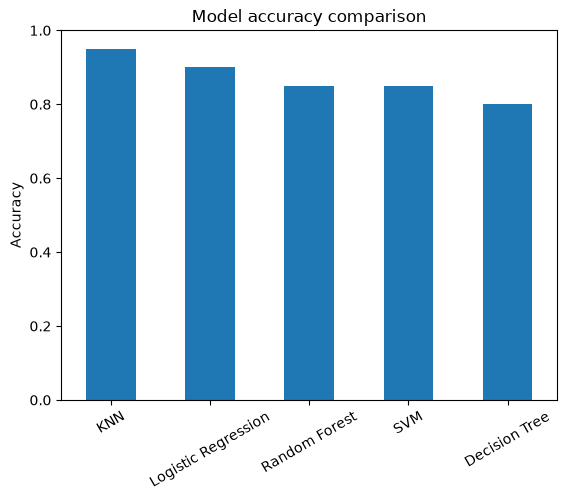

In [47]:
# Bar chart of the accuracies
import matplotlib.pyplot as plt
table.plot(kind="bar", title="Model accuracy comparison", ylabel="Accuracy", ylim=(0, 1))
plt.xticks(rotation=30); plt.show()

## L. Evaluate the best model: confusion matrix + classification report

```
               Predicted 0   Predicted 1
Actual 0          TN            FP
Actual 1          FN            TP
```
- **Accuracy** = (TP+TN)/total, the share of all predictions that were correct
- **Precision** = TP/(TP+FP): of the predicted Yes, how many were really Yes
- **Recall** = TP/(TP+FN): of the real Yes, how many we found
- **F1** = 2·P·R/(P+R), the balance of precision and recall

In [48]:
best_name = table.idxmax()                        # name of the best model
best = models[best_name]
best_pred = best.predict(X_test_s)
cm = confusion_matrix(y_test, best_pred)
print("Best:", best_name)
print("Confusion matrix:\n", cm)
tn, fp, fn, tp = cm.ravel()                        # unpack the 4 numbers
print("TN =", tn, " FP =", fp, " FN =", fn, " TP =", tp)
print(classification_report(y_test, best_pred))

Best: KNN
Confusion matrix:
 [[ 3  1]
 [ 0 16]]
TN = 3  FP = 1  FN = 0  TP = 16
              precision    recall  f1-score   support

           0       1.00      0.75      0.86         4
           1       0.94      1.00      0.97        16

    accuracy                           0.95        20
   macro avg       0.97      0.88      0.91        20
weighted avg       0.95      0.95      0.95        20



In [49]:
print("----- Actual vs predicted -----")
print(pd.DataFrame({"Actual": y_test.values, "Predicted": best_pred}).head(10))

----- Actual vs predicted -----
   Actual  Predicted
0       1          1
1       1          1
2       1          1
3       1          1
4       1          1
5       1          1
6       0          0
7       1          1
8       1          1
9       1          1


## M. Predict for a NEW customer

In [50]:
new = pd.DataFrame([[30, 50000, 1],      # age 30, income 50000, female
                    [22, 20000, 0]],     # age 22, income 20000, male
                   columns=X.columns)
new_s = sc.transform(new)                # use the SAME scaler
for row, p in zip(new.values, best.predict(new_s)):
    print(row, "->", "Will purchase (Yes)" if p == 1 else "Will NOT purchase (No)")

[   30 50000     1] -> Will purchase (Yes)
[   22 20000     0] -> Will NOT purchase (No)


## N. Regression: when the target is a NUMBER (predict Income)

In [51]:
Xr = data[["Age", "Gender"]]             # features
yr = data["Income"]                      # target is a number -> REGRESSION
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)

lin = LinearRegression()                 # straight line: y = m1*x1 + m2*x2 + c
lin.fit(Xr_train, yr_train)
lin_pred = lin.predict(Xr_test)

print("R2   :", round(r2_score(yr_test, lin_pred), 2))                    # 1 = perfect
print("MAE  :", round(mean_absolute_error(yr_test, lin_pred), 2))         # average error
print("MSE  :", round(mean_squared_error(yr_test, lin_pred), 2))          # average squared error
print("RMSE :", round(mean_squared_error(yr_test, lin_pred) ** 0.5, 2))   # sqrt of MSE, same unit as Income
print("Coefficients (Age, Gender):", lin.coef_.round(2))
print("Intercept:", round(lin.intercept_, 2))
print(pd.DataFrame({"Actual": yr_test.values, "Predicted": lin_pred.round(0)}).head())

R2   : 0.67
MAE  : 6555.08
MSE  : 61146197.25
RMSE : 7819.6
Coefficients (Age, Gender): [ 933.01 4967.68]
Intercept: 11776.47
    Actual  Predicted
0  61600.0    61226.0
1  71300.0    76457.0
2  60600.0    46600.0
3  40700.0    48164.0
4  65300.0    73658.0


In [52]:
print("----- Compare regression models -----")
reg_models = {"Linear Regression": LinearRegression(),
              "Decision Tree":     DecisionTreeRegressor(random_state=42),
              "Random Forest":     RandomForestRegressor(random_state=42)}
for name, m in reg_models.items():
    m.fit(Xr_train, yr_train)
    p = m.predict(Xr_test)
    print(f"{name:20s} R2 = {r2_score(yr_test, p):.2f}   MAE = {mean_absolute_error(yr_test, p):.0f}"
          f"   RMSE = {mean_squared_error(yr_test, p) ** 0.5:.0f}")
# Higher R2 = better; lower MAE/RMSE = better

----- Compare regression models -----
Linear Regression    R2 = 0.67   MAE = 6555   RMSE = 7820
Decision Tree        R2 = 0.30   MAE = 8692   RMSE = 11358
Random Forest        R2 = 0.59   MAE = 7004   RMSE = 8717


Predicted income: [44734.]
Income = 14687.05 + 910.29 x Age


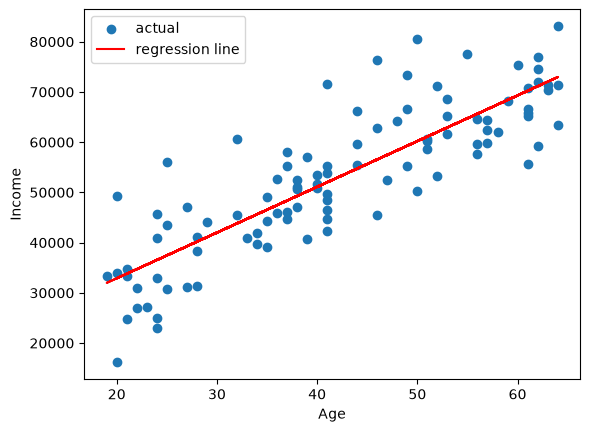

In [53]:
# Predict the income of a new person: age 30, female
print("Predicted income:", lin.predict(pd.DataFrame([[30, 1]], columns=Xr.columns)).round(0))

# Simple 1-feature line + plot
import matplotlib.pyplot as plt
simple = LinearRegression().fit(data[["Age"]], data["Income"])
print("Income =", round(simple.intercept_, 2), "+", round(simple.coef_[0], 2), "x Age")
plt.scatter(data["Age"], data["Income"], label="actual")
plt.plot(data["Age"], simple.predict(data[["Age"]]), color="red", label="regression line")
plt.xlabel("Age"); plt.ylabel("Income"); plt.legend(); plt.show()

## O. K-Means clustering (unsupervised, in case they ask)

In [ ]:
from sklearn.cluster import KMeans
Xc = StandardScaler().fit_transform(data[["Age", "Income"]])   # scale first

print("----- Elbow method: choose k where the drop slows down -----")
for k in range(1, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xc)
    print("k =", k, " inertia =", round(km.inertia_, 1))

km = KMeans(n_clusters=3, random_state=42, n_init=10)
data["Cluster"] = km.fit_predict(Xc)                 # cluster number for every row
print(data["Cluster"].value_counts())
print(data.groupby("Cluster")[["Age", "Income"]].mean().round(0))

----- Elbow method: choose k where the drop slows down -----


k = 1  inertia = 200.0
k = 2  inertia = 66.1
k = 3  inertia = 36.1
k = 4  inertia = 28.1
k = 5  inertia = 21.5
k = 6  inertia = 17.3
Cluster
1    40
0    39
2    21
Name: count, dtype: int64
          Age   Income
Cluster               
0        38.0  49379.0
1        56.0  66995.0
2        23.0  33071.0
